# WEEK 2 - DAY 4
## TASK 1: REGRESSION METRICS

Dataset Shape: (20640, 8)

First Five Rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Training Data Shape: (16512, 8)
Testing Data Shape: (4128, 8)

Regression Metrics Comparison:
            Model      MAE     RMSE        R2
Linear Regression 0.533200 0.745581  0.575788
    Random Forest 0.327731 0.505986  0.804624
         Baseline 0.906069 1.144856 -0.000219


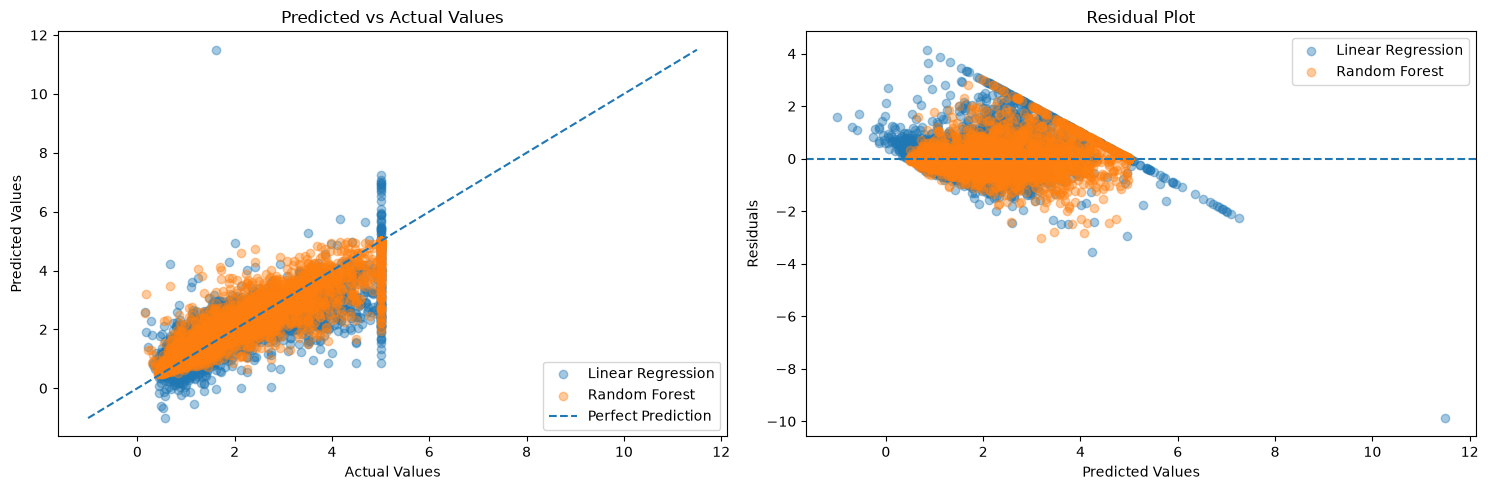


Explanation:
1. MAE measures the average absolute difference between actual and predicted values.
2. RMSE measures prediction errors and gives more importance to larger errors.
3. R-squared measures how much variation in the target is explained by the model.
4. An R-squared value of 0.6 means the model explains 60% of the variation in the target.


In [1]:
# 1. Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load California Housing Dataset

housing = fetch_california_housing()

X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target)

print("Dataset Shape:", X.shape)
print("\nFirst Five Rows:")
print(X.head())

# 3. Split Dataset into 80% Training and 20% Testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# 4. Train Linear Regression Model

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

# 5. Train Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# 6. Create Baseline Model (Predicts the Mean)

baseline_pred = np.full(
    len(y_test), y_train.mean()
)

# 7. Calculate MAE, RMSE and R-squared

def calculate_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

# Calculate metrics for all three models

lr_metrics = calculate_metrics(y_test, lr_pred)

rf_metrics = calculate_metrics(y_test, rf_pred)

baseline_metrics = calculate_metrics(y_test, baseline_pred)

# 8. Display Comparison Table

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Baseline"],
    "MAE": [lr_metrics[0], rf_metrics[0], baseline_metrics[0]],
    "RMSE": [lr_metrics[1], rf_metrics[1], baseline_metrics[1]],
    "R2": [lr_metrics[2], rf_metrics[2], baseline_metrics[2]]
})

print("\nRegression Metrics Comparison:")
print(results.to_string(index=False))

# 9. Plot Predicted vs Actual Values

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, lr_pred, alpha=0.4, label="Linear Regression")
plt.scatter(y_test, rf_pred, alpha=0.4, label="Random Forest")

min_value = min(y_test.min(), lr_pred.min(), rf_pred.min())
max_value = max(y_test.max(), lr_pred.max(), rf_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs Actual Values")
plt.legend()

# 10. Plot Residuals

lr_residuals = y_test - lr_pred
rf_residuals = y_test - rf_pred

plt.subplot(1, 2, 2)
plt.scatter(lr_pred, lr_residuals, alpha=0.4, label="Linear Regression")
plt.scatter(rf_pred, rf_residuals, alpha=0.4, label="Random Forest")

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.legend()

plt.tight_layout()
plt.show()

# 11. Explanation of MAE, RMSE and R-squared

print("\nExplanation:")
print("1. MAE measures the average absolute difference between actual and predicted values.")
print("2. RMSE measures prediction errors and gives more importance to larger errors.")
print("3. R-squared measures how much variation in the target is explained by the model.")
print("4. An R-squared value of 0.6 means the model explains 60% of the variation in the target.")

## TASK 2: HYPERPARAMETER TUNING

In [2]:
# 1. Import required libraries

import pandas as pd
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# 2. Load Breast Cancer Dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

# 3. Split Dataset into Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# 4. Create Random Forest Classifier

rf_model = RandomForestClassifier(random_state=42)

# 5. GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    return_train_score=True
)

start_time = time.time()

grid_search.fit(X_train, y_train)

grid_time = time.time() - start_time

print("\nGrid Search Results:")
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)
print("Time Taken:", round(grid_time, 2), "seconds")

# 6. Display Grid Search Cross-Validation Results

grid_results = pd.DataFrame(grid_search.cv_results_)

print("\nGrid Search Cross-Validation Results:")
print(
    grid_results[
        ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head(10).to_string(index=False)
)

# 7. RandomizedSearchCV

param_distributions = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [None, 5, 10, 15, 20, 30],
    'min_samples_leaf': [1, 2, 4, 6, 8]
}

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=20,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.time()

random_search.fit(X_train, y_train)

random_time = time.time() - start_time

print("\nRandomized Search Results:")
print("Best Parameters:", random_search.best_params_)
print("Best F1 Score:", random_search.best_score_)
print("Time Taken:", round(random_time, 2), "seconds")

# 8. Display Randomized Search Cross-Validation Results

random_results = pd.DataFrame(random_search.cv_results_)

print("\nRandomized Search Cross-Validation Results:")
print(
    random_results[
        ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head(10).to_string(index=False)
)

# 9. Compare Grid Search and Randomized Search

comparison = pd.DataFrame({
    'Search Method': ['GridSearchCV', 'RandomizedSearchCV'],
    'Best F1 Score': [
        grid_search.best_score_,
        random_search.best_score_
    ],
    'Time Taken (seconds)': [
        round(grid_time, 2),
        round(random_time, 2)
    ]
})

print("\nGrid Search vs Randomized Search:")
print(comparison.to_string(index=False))

# 10. Evaluate the Best Model Once on the Test Set

if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    best_method = "GridSearchCV"
else:
    best_model = random_search.best_estimator_
    best_method = "RandomizedSearchCV"

test_predictions = best_model.predict(X_test)

test_f1 = f1_score(y_test, test_predictions)

print("\nFinal Best Model Evaluation:")
print("Selected Method:", best_method)
print("Test F1 Score:", test_f1)

# 11. Why We Should Not Tune on the Test Set

print("\nWhy We Should Not Tune on the Test Set:")
print("1. The test set must remain unseen during model tuning.")
print("2. Tuning on test data causes data leakage and overfitting.")
print("3. The test set should be used only for final model evaluation.")

Dataset Shape: (569, 30)
Target Shape: (569,)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)

Grid Search Results:
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best F1 Score: 0.9684436877471334
Time Taken: 43.61 seconds

Grid Search Cross-Validation Results:
                                                         params  mean_test_score  std_test_score  rank_test_score
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}         0.968444        0.015105                1
  {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}         0.968444        0.015105                1
  {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}         0.968444        0.015105                1
{'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 100}         0.966828        0.019962                4
  {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 100}         0.966828        0.019962                4
  {'ma

## BONUS CHALLENGE
### XGBOOST HYPERPARAMETER TUNING

In [3]:
# 1. Import required libraries

import pandas as pd
import time

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score

# 2. Create XGBoost Classifier

xgb_model = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    n_jobs=1
)

# 3. Define Hyperparameter Range

xgb_param_distributions = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

# 4. Apply RandomizedSearchCV

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_distributions,
    n_iter=20,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

# 5. Train and Measure Execution Time

start_time = time.time()

xgb_random_search.fit(X_train, y_train)

xgb_time = time.time() - start_time

# 6. Print Best Parameters and Best F1 Score

print("XGBoost Randomized Search Results:")
print("Best Parameters:", xgb_random_search.best_params_)
print("Best F1 Score:", xgb_random_search.best_score_)
print("Time Taken:", round(xgb_time, 2), "seconds")

# 7. Display Cross-Validation Results as DataFrame

xgb_results = pd.DataFrame(xgb_random_search.cv_results_)

print("\nXGBoost Cross-Validation Results:")

print(
    xgb_results[
        ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head(10).to_string(index=False)
)

# 8. Evaluate Tuned XGBoost on Test Data

best_xgb_model = xgb_random_search.best_estimator_

xgb_predictions = best_xgb_model.predict(X_test)

xgb_test_f1 = f1_score(y_test, xgb_predictions)

print("\nXGBoost Test F1 Score:", xgb_test_f1)

# 9. Compare XGBoost with Tuned Random Forest

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Best CV F1 Score': [
        random_search.best_score_,
        xgb_random_search.best_score_
    ],
    'Test F1 Score': [
        f1_score(y_test, random_search.best_estimator_.predict(X_test)),
        xgb_test_f1
    ],
    'Time Taken (seconds)': [
        random_time,
        round(xgb_time, 2)
    ]
})

print("\nRandom Forest vs XGBoost Comparison:")
print(comparison.to_string(index=False))

XGBoost Randomized Search Results:
Best Parameters: {'subsample': 0.9, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
Best F1 Score: 0.9826376285541439
Time Taken: 23.94 seconds

XGBoost Cross-Validation Results:
                                                                                                 params  mean_test_score  std_test_score  rank_test_score
{'subsample': 0.9, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.9}         0.982638        0.018888                1
{'subsample': 0.9, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.9}         0.980988        0.014716                2
{'subsample': 0.9, 'n_estimators': 400, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.9}         0.980898        0.017563                3
{'subsample': 0.9, 'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}         0.980895        0.014